# Supplemental Figure 3, Panel B

Lineplots showing proportion of BAF-dep (significantly decreasing accessibility) primed and active enhancers across BAFinh time and dose

*Output: PanelB.pdf*

# Setup

In [5]:
# load packages
library(tidyverse)
library(readr)
library(purrr)
library(patchwork)
library(here)
here::i_am("figures/SuppFig3/PanelB/PanelB.ipynb")

theme_set(theme_bw() + theme(panel.grid=element_blank()))

sessionInfo()

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig3/PanelB

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      patchwork_1.3.0 lubridate_1.9.4 forcats_1.0.0  
 [5] stringr_1.5.1   dplyr_1.1.4     purrr_1.0.2     readr_2.1.5    
 [9] tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pbdZMQ_0.3-13     tidyselect_1.2.1  re

# Load data and calculate % BAFdep

In [6]:
# cRE annotations
states <- read.delim(
  here("inputs", "bed", "ATAC_peaks", "filtered", "consensus_filt_annot.tsv"),
  sep = "\t"
)

# paths to differential accessibility analysis results
dose_files <- list.files(
  here("inputs", "DARs"),
  pattern    = "dose",
  full.names = TRUE
)

time_files <- list.files(
  here("inputs", "DARs"),
  pattern    = "time_",
  full.names = TRUE
)

# Read, sort, and extract BAFdep column
#dose
dose_df <- dose_files %>%
  map(~ read_tsv(.x, show_col_types = FALSE) %>%
        arrange(seqnames, start) %>%
        pull(BAFdep)) %>%
  set_names(basename(dose_files)) %>%
  bind_cols() %>% mutate(type=states$type)

#time
time_df <- time_files %>%
  map(~ read_tsv(.x, show_col_types = FALSE) %>%
        arrange(seqnames, start) %>%
        pull(BAFdep)) %>%
  set_names(basename(time_files)) %>%
  bind_cols() %>% mutate(type=states$type)


# Generate plots

In [3]:
#plot % of cREs that are BAFdep over dose (top) and time (bottom)

dose_plot <- dose_df %>% `colnames<-`(c("d100n", "d10n", "d10u", "d1u", "type")) %>% pivot_longer(!type) %>% 
    mutate(name=factor(name, levels=c("d10n", "d100n", "d1u", "d10u"))) %>%
    group_by(name, type) %>% summarize(n_bafdep=sum(value), n_total=n(), pct=100*n_bafdep/n_total,.groups="drop") %>%
    filter(type %in% c("active_enh", "poised_enh")) %>%
    ggplot(aes(x=name,y=pct, group=type, color=type)) +
    geom_hline(yintercept=c(0,100), linetype=2) + 
    geom_point() + geom_line() + 
    scale_color_manual(values=c("active_enh"="#f2bf4b", "poised_enh"="#c28c2c")) +
    ggtitle("BAFinh Dose (µM)")

time_plot <- time_df %>% `colnames<-`(c("t0.5", "t1", "t24", "t2", "t6", "type")) %>% pivot_longer(!type) %>% 
    mutate(name=factor(name, levels=c("t0.5", "t1", "t2", "t6", "t24"))) %>%
    group_by(name, type) %>% summarize(n_bafdep=sum(value), n_total=n(), pct=100*n_bafdep/n_total,.groups="drop") %>%
    filter(type %in% c("active_enh", "poised_enh")) %>%
    ggplot(aes(x=name,y=pct, group=type, color=type)) +
    geom_hline(yintercept=c(0,100), linetype=2) + 
    geom_point() + geom_line() + 
    scale_color_manual(values=c("active_enh"="#f2bf4b", "poised_enh"="#c28c2c")) +
    ggtitle("BAFinh Duration (h)")



# Assemble figure panel

Saving 7 x 3 in image


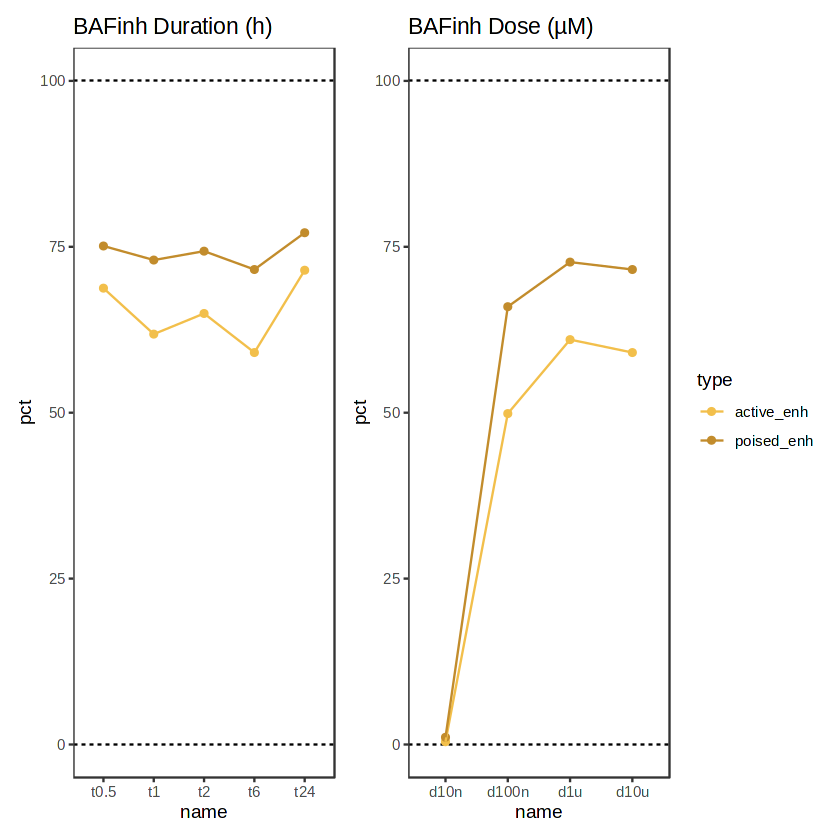

In [4]:
(time_plot | dose_plot) + plot_layout(guides="collect")
ggsave("PanelB.pdf", height=3)